In [31]:
import pandas as pd
import ast
import networkx as nx
from networkx.algorithms import bipartite
import matplotlib.pyplot as plt

In [34]:
## Importing and Exploring the Data

## Topic: which skills data jobs ask for and how that differs between analysts, engineers, and scientists.
## two groups: jobs and skills

url = "https://huggingface.co/datasets/lukebarousse/data_jobs/resolve/main/data_jobs.csv"
df = pd.read_csv(url)
print(df.shape)
print(df[["job_title_short", "job_country", "job_skills"]].head())

(785741, 17)
        job_title_short    job_country  \
0  Senior Data Engineer  United States   
1          Data Analyst         Mexico   
2         Data Engineer        Germany   
3         Data Engineer  United States   
4         Data Engineer          Sudan   

                                          job_skills  
0                                                NaN  
1  ['r', 'python', 'sql', 'nosql', 'power bi', 't...  
2  ['python', 'sql', 'c#', 'azure', 'airflow', 'd...  
3  ['python', 'c++', 'java', 'matlab', 'aws', 'te...  
4  ['bash', 'python', 'oracle', 'aws', 'ansible',...  


In [23]:
## Building the 2-mode network

## Cleaning the data and only keeping US jobs to keep the data and inferences we make consistent
## Selecting a working random sample size of 3000
us = df[df["job_country"] == "United States"]
us = us.dropna(subset=["job_skills"])
sample = us.sample(3000, random_state=1)

G=nx.Graph()
for i, row in sample.iterrows():
    job = "job_" + str(i)
    G.add_node(job, kind="job", title=row["job_title_short"])
    for skill in ast.literal_eval(row["job_skills"]):
        G.add_node(skill, kind="skill")
        G.add_edge(job, skill)

jobs = [n for n in G if G.nodes[n]["kind"] == "job"]
skills = [n for n in G if G.nodes[n]["kind"] == "skill"]
print(len(jobs), "jobs", len(skills), "skills", G.number_of_edges(), "links") 

3000 jobs 187 skills 16742 links


In [26]:
## Skills-Only Network --> Tunrnig Jobs to Skills to Skills to Skills. Two skills are linked when the same job asks for both
## weight is determined by how many jobs asked for both

S = bipartite.weighted_projected_graph(G, skills)

print(S.number_of_nodes(), "skills", S.number_of_edges(), "skills pairs")
print("python and sql appear together in", S["python"]["sql"]["weight"], "jobs")

pairs = sorted(S.edges(data="weight"), key=lambda e: e[2], reverse=True)
for a, b, w in pairs[:10]:
    print(a, "+", b, ":", w, "jobs")

187 skills 5521 skills pairs
python and sql appear together in 1214 jobs
sql + python : 1214 jobs
python + r : 767 jobs
sql + tableau : 608 jobs
sql + r : 578 jobs
aws + python : 519 jobs
python + tableau : 503 jobs
python + spark : 452 jobs
sql + aws : 449 jobs
sql + excel : 447 jobs
sql + spark : 369 jobs


In [27]:
## Shrink it with the island Method
## Keeping what stays connected , Python and SQL are so connected in so many jobs they connect the entire network

for level in [50, 100, 200, 400]:
    keep = [(a, b) for a, b, w in S.edges(data="weight") if w >= level]
    islands = list(nx.connected_components(nx.Graph(keep)))
    print("level", level, ":", len(islands), "islands, sizes:", sorted([len(c) for c in islands], reverse=True))

level 50 : 1 islands, sizes: [54]
level 100 : 1 islands, sizes: [34]
level 200 : 1 islands, sizes: [14]
level 400 : 1 islands, sizes: [7]


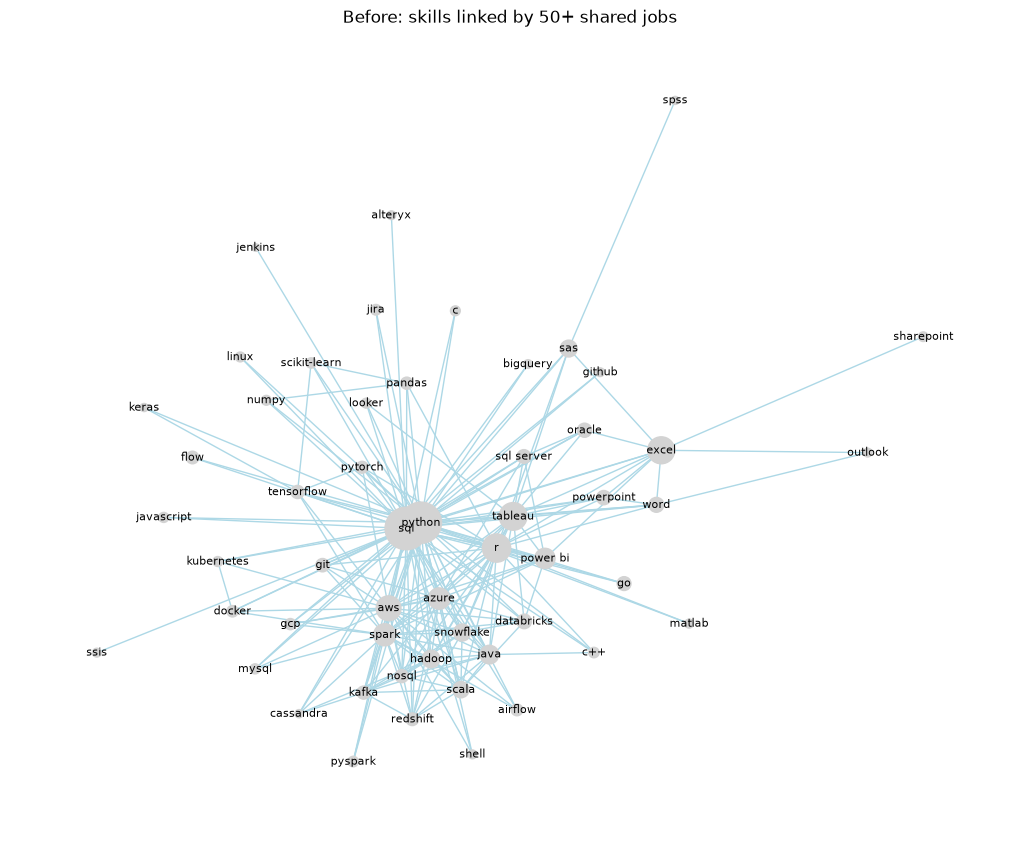

In [32]:
## Displaying how everything is connected by python and Sql in the network graph 

before = nx.Graph([(a, b) for a, b, w in S.edges(data="weight") if w >= 50])
sizes = [count[n] / 2 for n in before]

plt.figure(figsize=(10, 8))
nx.draw(before, nx.spring_layout(before, seed=1), with_labels=True, node_size=sizes,
        node_color="lightgray", edge_color="lightblue", font_size=8)
plt.title("Before: skills linked by 50+ shared jobs")
plt.show()

In [28]:
## Island Method with percent overlap
## of the jobs that want either skill, what share want both?

count = dict(G.degree(skills))

for a, b, w in S.edges(data="weight"):
    S[a][b]["overlap"] = w / (count[a] + count[b] - w)

print("python + sql overlap:", round(S["python"]["sql"]["overlap"], 2))

for level in [0.1, 0.2, 0.3, 0.4, 0.5]:
    keep = [(a, b) for a, b, o in S.edges(data="overlap") if o >= level and S[a][b]["weight"] >= 10]
    islands = list(nx.connected_components(nx.Graph(keep)))
    print("level", level, ":", len(islands), "islands, sizes:", sorted([len(c) for c in islands], reverse=True))

python + sql overlap: 0.5
level 0.1 : 2 islands, sizes: [62, 3]
level 0.2 : 6 islands, sizes: [23, 6, 2, 2, 2, 2]
level 0.3 : 7 islands, sizes: [4, 3, 3, 2, 2, 2, 2]
level 0.4 : 4 islands, sizes: [3, 2, 2, 2]
level 0.5 : 3 islands, sizes: [2, 2, 2]


In [29]:
## listing the skills on each island at 0.2 and 0.3 to pick clearest level

for level in [0.2, 0.3]:
    keep = [(a, b) for a, b, o in S.edges(data="overlap") if o >= level and S[a][b]["weight"] >= 10]
    islands = sorted(nx.connected_components(nx.Graph(keep)), key=len, reverse=True)
    print("LEVEL", level)
    for n, island in enumerate(islands, start=1):
        print("  Island", n, ":", sorted(island))
    print()

LEVEL 0.2
  Island 1 : ['aws', 'azure', 'c++', 'cassandra', 'databricks', 'excel', 'hadoop', 'java', 'kafka', 'mongo', 'mongodb', 'nosql', 'outlook', 'power bi', 'powerpoint', 'python', 'r', 'scala', 'shell', 'spark', 'sql', 'tableau', 'word']
  Island 2 : ['keras', 'numpy', 'pandas', 'pytorch', 'scikit-learn', 'tensorflow']
  Island 3 : ['docker', 'kubernetes']
  Island 4 : ['confluence', 'jira']
  Island 5 : ['ssis', 'ssrs']
  Island 6 : ['css', 'html']

LEVEL 0.3
  Island 1 : ['hadoop', 'java', 'scala', 'spark']
  Island 2 : ['python', 'r', 'sql']
  Island 3 : ['keras', 'pytorch', 'tensorflow']
  Island 4 : ['docker', 'kubernetes']
  Island 5 : ['powerpoint', 'word']
  Island 6 : ['numpy', 'pandas']
  Island 7 : ['css', 'html']



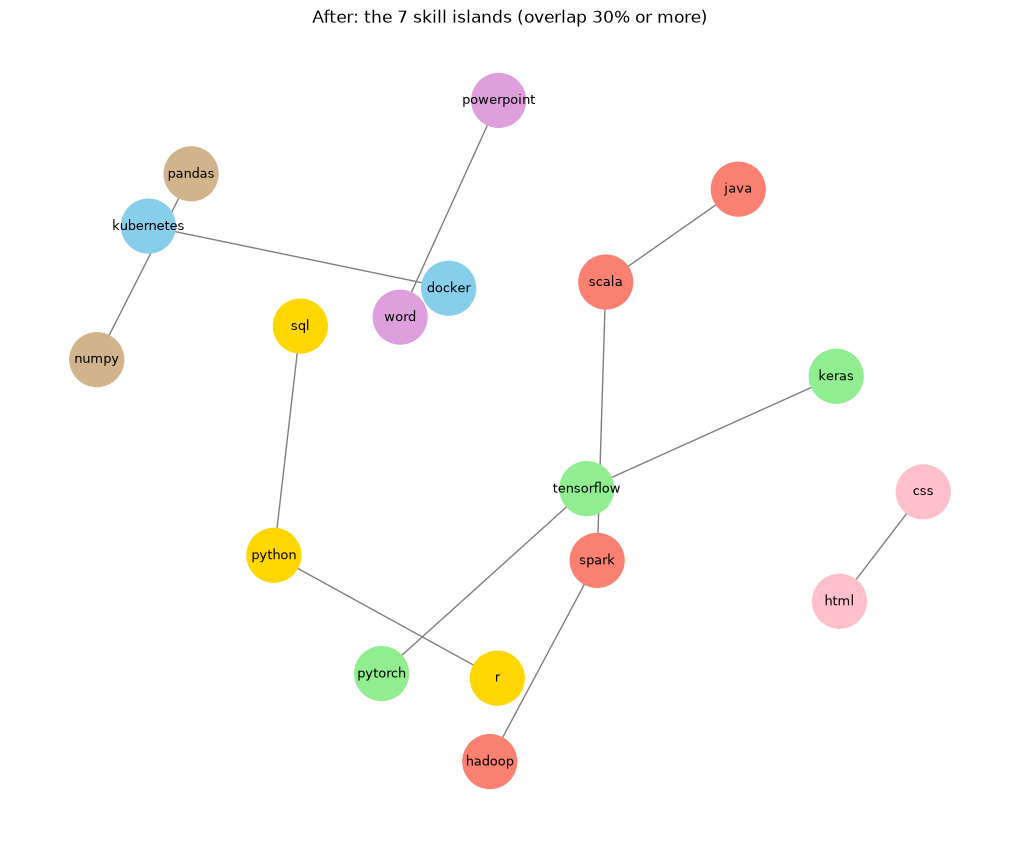

In [33]:
## After creating 7 islands, a clear comparison to the intital graph. what skills are clearly linked and what those packages are

keep = [(a, b) for a, b, o in S.edges(data="overlap") if o >= 0.3 and S[a][b]["weight"] >= 10]
after = nx.Graph(keep)
islands = sorted(nx.connected_components(after), key=len, reverse=True)

colors = ["salmon", "gold", "lightgreen", "skyblue", "plum", "tan", "pink"]
color_of = {}
for i, island in enumerate(islands):
    for skill in island:
        color_of[skill] = colors[i]

plt.figure(figsize=(10, 8))
nx.draw(after, nx.spring_layout(after, seed=1, k=1), with_labels=True, node_size=1500,
        node_color=[color_of[n] for n in after], edge_color="gray", font_size=9)
plt.title("After: the 7 skill islands (overlap 30% or more)")
plt.show()

In [30]:
## Which islands does each job title use?

## Creating a dictionary 
island_skills = {
    "Core": ["python", "r", "sql"],
    "BigData": ["hadoop", "java", "scala", "spark"],
    "DeepLearn": ["keras", "pytorch", "tensorflow"],
    "PyTools": ["numpy", "pandas"],
    "Deploy": ["docker", "kubernetes"],
    "Office": ["powerpoint", "word"],
    "Web": ["css", "html"],
}

rows = []
for job in jobs:
    job_skills = set(G[job])
    row = {"title": G.nodes[job]["title"]}
    for name, island in island_skills.items():
        row[name] = len(job_skills & set(island)) > 0
    rows.append(row)

pd.set_option("display.max_columns", None)
table = pd.DataFrame(rows).groupby("title").mean() * 100
print(table.round(0))

                           Core  BigData  DeepLearn  PyTools  Deploy  Office  \
title                                                                          
Business Analyst           61.0      5.0        0.0      1.0     0.0    21.0   
Cloud Engineer             38.0     25.0        0.0      0.0     0.0    25.0   
Data Analyst               70.0      7.0        1.0      2.0     0.0    18.0   
Data Engineer              87.0     48.0        1.0      5.0    14.0     3.0   
Data Scientist             91.0     34.0       17.0     10.0     6.0     7.0   
Machine Learning Engineer  92.0     50.0       42.0      4.0    12.0     0.0   
Senior Data Analyst        82.0     10.0        1.0      3.0     1.0    14.0   
Senior Data Engineer       88.0     60.0        1.0      1.0    19.0     3.0   
Senior Data Scientist      92.0     33.0       21.0     15.0     7.0     3.0   
Software Engineer          71.0     42.0        0.0     12.0     0.0    12.0   

                           Web  
title 

In [ ]:
## Conclusions 

# We shrunk a network of 3000 job + 187 skills + 16,742 links into a skills network of 5,521 pairs
# The raw count was far too connected by 3 skills that were apparent in every job, SQL, R, and PYTHON
# Using percent overalp we created 7 islands or pairings between skills

# Skills
# What we can infer about the distinct groups is that employers ask for skills in packages and not just indiviual skills, if they ask for 1 they will most likely require the other one. 
# We created 7 packages that employers really look at: Core Languages (python,r, sql), Big Data(hadoop, java, scala, spark), Deep Learning(keras, pytorch, tensorflow), Office (powerpoint, word), Python Data Tools(numpy, pandas), Web(css, html) and Deployment(docker, kubernetes)
# Python + SQL is the strongest pair along with R. Half of the job listings look for both

#Jobs
# Core languages(python, r, sql) are everywhere
# Analysts require the least technical skills, they need core and office which makes sense they have a handle on presenting the data
# Engineers require core, big data, and deployment abilities
# Data Scientis and ML engineers require core, big data and deep learning, with an emphasis on AI tools
# Web skills have the least importance for data jobs and are at 4% or less for all titles 
